# Teks — Tanya Jawab Ekstraktif (jawaban = potongan dari konteks)
**Kapan dipakai:** diberi pertanyaan + paragraf, cari potongan teks yang menjawab.

**Cara:** model QA pretrained langsung dipakai tanpa latih (mDeBERTa SQuAD2 multibahasa,
`pretrained/qa_mdeberta`). Model memberi skor "awal jawaban" dan "akhir jawaban" untuk tiap
token konteks; jawaban = pasangan (awal, akhir) dengan skor tertinggi.

**Metrik gaya SQuAD:** Exact Match (jawaban persis) dan F1 token (irisan kata).

**Data demo:** FacQA (berita Indonesia). Di data latihan, file test masih punya kolom
`jawaban` (untuk sel kunci).

In [1]:
import re
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import AutoModelForQuestionAnswering, AutoTokenizer

## Konfigurasi

In [2]:
DATA_FOLDER = "../../../data_latihan/text/qa"   # GANTI saat lomba
TRAIN_CSV = f"{DATA_FOLDER}/facqa_train.csv"
VALID_CSV = f"{DATA_FOLDER}/facqa_valid.csv"
TEST_CSV = f"{DATA_FOLDER}/facqa_test.csv"
QA_MODEL = "../../../pretrained/qa_mdeberta"

QUESTION_COL = "pertanyaan"
CONTEXT_COL = "konteks"
ANSWER_COL = "jawaban"
MAX_ANSWER_TOKENS = 15     # naikkan (mis. 30) bila jawaban sering terpotong
MAX_LENGTH = 384           # panjang maksimal pertanyaan + konteks (token)
DEVICE = "cpu"
if torch.cuda.is_available():
    DEVICE = "cuda"

## Baca data

In [3]:
train = pd.read_csv(TRAIN_CSV)
valid = pd.read_csv(VALID_CSV)
test = pd.read_csv(TEST_CSV)
print("train:", train.shape, "| valid:", valid.shape, "| test:", test.shape)
train.head()

train: (2495, 4) | valid: (311, 4) | test: (311, 4)


,id,pertanyaan,konteks,jawaban
0,0,Kelompok apakah yang menyatakan bertanggung ja...,Lewat telepon ke kantor berita lokal Current N...,Hezb-ul Mujahedeen
1,1,"Di pulau manakah , PT Mutiara Indopearl berlok...",Sejak tahun 1980 - an di Kota Bau-Bau terdapat...,Pulau Makassar
2,2,Apakah warna pasir pada pesisir pantai Baturum...,Titik kedua adalah Pantai Baturumah sepanjang ...,putih halus
3,3,Apa nama perusahaan China yang bekerja sama de...,"Sichuan , Kompas - Pemerintah Indonesia dan Ch...",Sinopec Southwest Petroleum Biro
4,4,Siapa yang akan memindahkan Patung Kartini dal...,"Jakarta , Kompas - Patung Kartini di Jalan Tam...",Pemerintah DKI Jakarta


## EDA: panjang konteks, panjang jawaban, kata tanya

kata per konteks:
count    2495.0
mean       49.9
std        16.7
min         5.0
25%        38.0
50%        48.0
75%        58.0
max       121.0
Name: konteks, dtype: float64


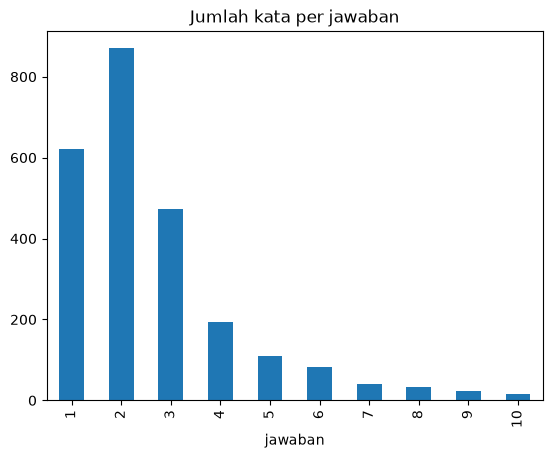

pertanyaan
siapakah     325
apa          233
berapa       212
apakah       186
berapakah    153
siapa        142
di           137
kapan        113
Name: count, dtype: int64


In [4]:
context_words = train[CONTEXT_COL].str.split().str.len()
print("kata per konteks:")
print(context_words.describe().round(1))

answer_words = train[ANSWER_COL].str.split().str.len()
answer_word_counts = answer_words.value_counts().sort_index()
answer_word_counts.head(10).plot.bar()
plt.title("Jumlah kata per jawaban")
plt.show()

question_word = train[QUESTION_COL].str.split().str[0]
question_word = question_word.str.lower()
print(question_word.value_counts().head(8))

## Metrik: Exact Match dan F1 token
Teks dinormalisasi dulu: huruf kecil, tanda baca dibuang, dipecah per kata.

In [5]:
def normalize(text):
    text = re.sub(r"[^\w\s]", " ", str(text).lower())
    return text.split()


def token_f1(prediction, truth):
    common = Counter(normalize(prediction)) & Counter(normalize(truth))
    n_same = sum(common.values())
    if n_same == 0:
        return 0.0
    precision = n_same / len(normalize(prediction))
    recall = n_same / len(normalize(truth))
    return 2 * precision * recall / (precision + recall)


print(token_f1("Presiden Joko Widodo", "Joko Widodo"))

0.8


## Model QA

In [6]:
tokenizer = AutoTokenizer.from_pretrained(QA_MODEL)
model = AutoModelForQuestionAnswering.from_pretrained(QA_MODEL)
model = model.to(DEVICE)
model.eval()

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

DebertaV2ForQuestionAnswering(
  (deberta): DebertaV2Model(
    (embeddings): DebertaV2Embeddings(
      (word_embeddings): Embedding(251000, 768, padding_idx=0)
      (LayerNorm): LayerNorm((768,), eps=1e-07, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): DebertaV2Encoder(
      (layer): ModuleList(
        (0-11): 12 x DebertaV2Layer(
          (attention): DebertaV2Attention(
            (self): DisentangledSelfAttention(
              (query_proj): Linear(in_features=768, out_features=768, bias=True)
              (key_proj): Linear(in_features=768, out_features=768, bias=True)
              (value_proj): Linear(in_features=768, out_features=768, bias=True)
              (pos_dropout): Dropout(p=0.1, inplace=False)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): DebertaV2SelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm(

## Fungsi menjawab satu pertanyaan
1. Tokenisasi pertanyaan + konteks. `offsets` = posisi huruf tiap token di konteks.
2. Model memberi skor awal dan akhir untuk tiap token.
3. Cari pasangan (awal, akhir) di dalam konteks dengan skor total tertinggi, panjang maksimal
   `MAX_ANSWER_TOKENS`.

In [7]:
def answer(question, context):
    encoded = tokenizer(question, context, truncation="only_second", max_length=MAX_LENGTH,
                        return_offsets_mapping=True, return_tensors="pt")
    offsets = encoded.pop("offset_mapping")[0].numpy()
    in_context = np.array(encoded.sequence_ids(0)) == 1
    with torch.no_grad():
        output = model(**encoded.to(DEVICE))
    start_scores = output.start_logits[0].cpu().numpy()
    end_scores = output.end_logits[0].cpu().numpy()
    best_score = -np.inf
    best_start = 0
    best_end = 0
    for start in np.where(in_context)[0]:
        for end in range(start, min(start + MAX_ANSWER_TOKENS, len(end_scores))):
            score = start_scores[start] + end_scores[end]
            if in_context[end] and score > best_score:
                best_score = score
                best_start = start
                best_end = end
    return context[offsets[best_start][0]:offsets[best_end][1]].strip()


# coba pada contoh validasi pertama
print("pertanyaan:", valid.loc[0, QUESTION_COL])
print("jawaban model:", answer(valid.loc[0, QUESTION_COL], valid.loc[0, CONTEXT_COL]))
print("jawaban asli :", valid.loc[0, ANSWER_COL])

pertanyaan: Apa nama latin dari harimau Sumatera ?


jawaban model: Panthera tigris sumatrensis
jawaban asli : Panthera tigris sumatrensis


## Evaluasi di data validasi

In [8]:
val_predictions = []
for question, context in zip(valid[QUESTION_COL], valid[CONTEXT_COL]):
    val_predictions.append(answer(question, context))

exact_matches = []
f1_scores = []
for prediction, truth in zip(val_predictions, valid[ANSWER_COL]):
    exact_matches.append(normalize(prediction) == normalize(truth))
    f1_scores.append(token_f1(prediction, truth))
print("Exact Match:", round(np.mean(exact_matches), 4), "| F1 token:", round(np.mean(f1_scores), 4))

examples = valid[[QUESTION_COL, ANSWER_COL]].copy()
examples["prediksi"] = val_predictions
pd.set_option("display.max_colwidth", 80)
examples.head(10)

Exact Match: 0.6463 | F1 token: 0.8532


,pertanyaan,jawaban,prediksi
0,Apa nama latin dari harimau Sumatera ?,Panthera tigris sumatrensis,Panthera tigris sumatrensis
1,Berapa penumpang yang turut dalam penerbangan GA - 181 jurusan Medan-Jakarta...,84 penumpang,84
2,Kepala Badan apakah Mohamed ElBaradei ?,Badan Tenaga Atom Internasional ( IAEA ),Kepala Badan Tenaga Atom Internasional
3,Berapa kalikah Lin Dan gagal memainkan netting saat melawan Taufik Hidayat d...,15 kali,15
4,Apakah nama fakultas tempat Drh Yuda Heru Fibrianto MS menjadi dosen ?,Fakultas Kedokteran Hewan,Fakultas Kedokteran Hewan UGM
5,Berapa jumlah suku yang tinggal di sekitar pantai selatan dan utara serta di...,253 suku,253
6,Siapakah nama wakil presiden Dialog Inter Amerika ?,Michael Shifter,Michael Shifter
7,"Sedang tugas belajar dimanakah Drh Yuda Heru Fibrianto MS , dosen Fakultas K...","Seoul National University , Korea","Seoul National University , Korea Selatan"
8,"Pada saat ini , berapakah jumlah penyu belimbing yang terdapat di pantai Jam...",4.000 ekor,lebih dari 4.000 ekor
9,Apakah nama latin dari penyu hijau,Chelonia mydas,Chelonia mydas


## Prediksi test + submission (model tidak dilatih, langsung dipakai)

In [9]:
predictions = []
for question, context in zip(test[QUESTION_COL], test[CONTEXT_COL]):
    predictions.append(answer(question, context))

submission = pd.DataFrame()
submission["id"] = test["id"]
submission["jawaban"] = predictions
submission.to_csv("submission.csv", index=False)
submission.head()

,id,jawaban
0,0,Christian Hadinata
1,1,Tony Blair
2,2,"49,07 detik"
3,3,Muntiacus muntjak
4,4,Susilo Bambang Yudhoyono


## Cek dengan kunci jawaban latihan
**HAPUS sel ini saat lomba**: kolom `jawaban` di file test hanya ada di data latihan.

In [10]:
test_f1 = []
for prediction, truth in zip(predictions, test[ANSWER_COL]):
    test_f1.append(token_f1(prediction, truth))
print("F1 token test (kunci latihan):", round(np.mean(test_f1), 4))

F1 token test (kunci latihan): 0.8778
